# <center>Computação Numérica — Projeto da Unidade II</center>
## <center>Modelando um sistema dinâmico com RBF e MMQ</center>

**Objetivo:** temos os sinais medidos (com ruído) de um sistema físico em operação. Queremos um modelo matemático que reproduza a dinâmica desse sistema e avaliar esse modelo com o **Erro Médio Quadrático (EMQ)** e a **Correlação de Pearson ($r$)**.

### Os dados (`dados_projeto_02.csv`)
| Coluna | Significado |
|---|---|
| `t` | tempo (s), de 0 a 30 s, uma amostra a cada $\Delta t = 0{,}02$ s (1501 amostras) |
| `u` | **entrada** do sistema: onda quadrada que alterna entre $+1$ e $-1$ |
| `x_ruido` | **saída 01**, medida com ruído |
| `y_ruido` | **saída 02**, medida com ruído |

### O modelo pedido no enunciado
$$y[n] = f\big(y[n-2],\; y[n-1],\; u[n],\; u[n-1]\big)$$
O valor da saída **agora** (instante $n$) depende dos **dois valores anteriores** da própria saída e dos valores **atual e anterior** da entrada. Fazemos o mesmo para a saída $x$. A função $f$ é obtida de duas formas:
* **RBF (Funções de Base Radial):** $f$ é uma soma de gaussianas (função não linear);
* **MMQ (Método dos Mínimos Quadrados):** $f$ é uma combinação linear dos 4 valores.

### Onde está cada item da avaliação
| Item do enunciado | Pontos | Seção |
|---|---|---|
| Ajuste via RBF | 2,0 | 4 (Etapa 01) |
| Erro Médio Quadrático (EMQ) | 1,0 | 4 (Etapa 02) |
| Regressão linear entre dados reais e ajustados | 1,0 | 4 (Etapa 03) |
| Coeficiente de Correlação de Pearson | 2,0 | 4 (Etapa 03) |
| Repetir o processo com MMQ | 2,0 | 5 (Etapa 04) |
| Parâmetros livres do modelo | — | 4.4 (RBF) e 5.1 (MMQ) |
| Conclusões | 2,0 | 8 |

Bibliotecas: apenas **NumPy** (vetores e álgebra linear) e **Matplotlib** (gráficos). EMQ, Pearson, regressão, RBF e equação normal foram escritos à mão.

In [1]:
import csv
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.5})
COR_MEDIDO = "#2a78d6"   # azul: dados medidos
COR_RBF = "#eb6834"      # laranja: modelo RBF
COR_MMQ = "#6250d6"      # roxo: modelo MMQ

---
## 1. Leitura dos dados

O arquivo usa **vírgula como separador decimal** (`"0,02"`), e esses números vêm entre aspas para não se confundirem com a vírgula que separa as colunas. Por isso:
1. o módulo `csv` separa as 4 colunas respeitando as aspas;
2. trocamos `,` por `.` em cada valor e convertemos para número (`float`).

Colunas: ['t', 'u', 'x_ruido', 'y_ruido']
N = 1501 amostras | t de 0.0 a 30.0 s | Δt = 0.02 s
x varia de -0.42 a 0.41 | y varia de -0.78 a 0.69 | u assume [-1.  0.  1.]


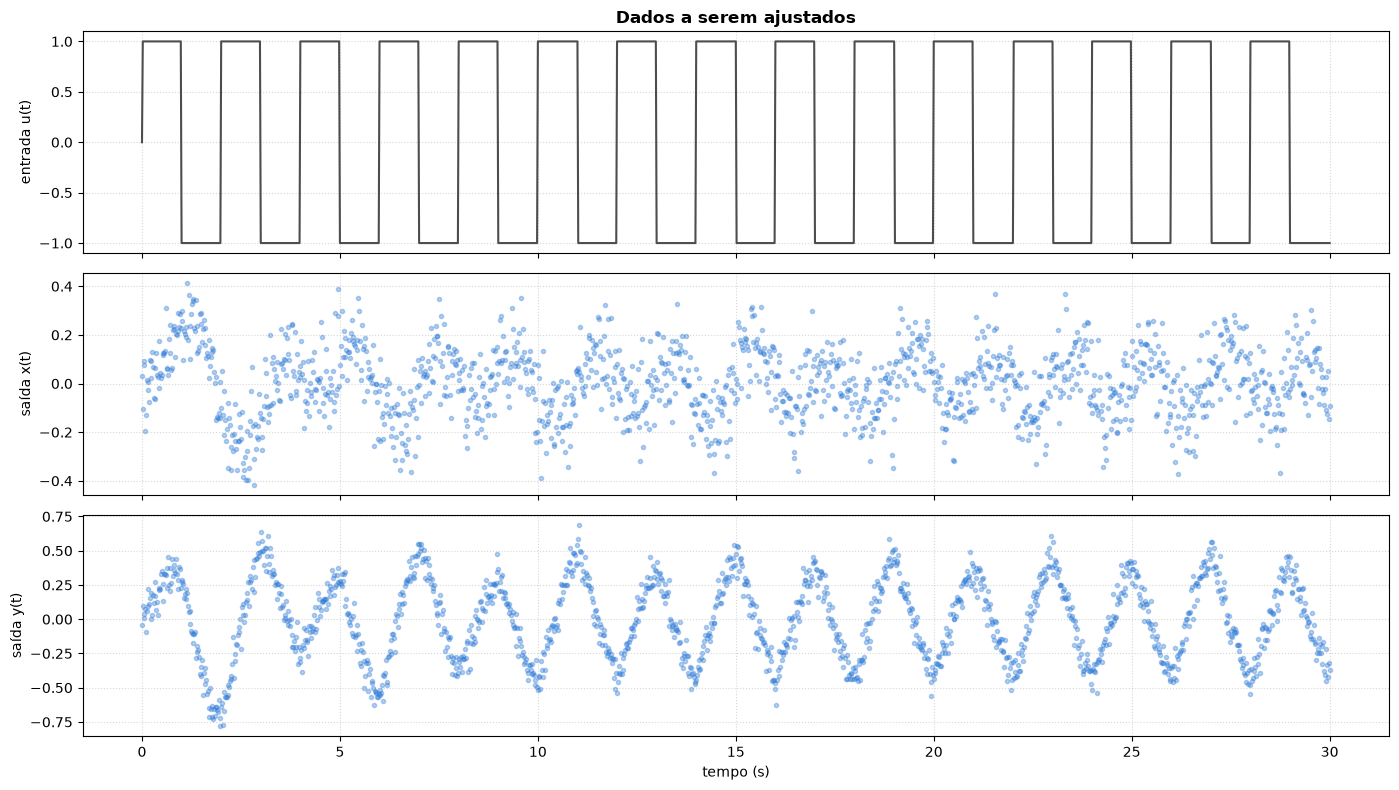

In [2]:
linhas = []
with open("dados_projeto_02.csv", "r", encoding="utf-8") as arquivo:
    leitor = csv.reader(arquivo)
    cabecalho = next(leitor)              # primeira linha: nomes das colunas
    for linha in leitor:
        if linha:                         # ignora linhas vazias
            linhas.append([float(valor.replace(",", ".")) for valor in linha])

dados = np.array(linhas)
t = dados[:, 0]   # tempo
u = dados[:, 1]   # entrada
x = dados[:, 2]   # saída 01
y = dados[:, 3]   # saída 02
N = len(t)

print("Colunas:", cabecalho)
print(f"N = {N} amostras | t de {t[0]} a {t[-1]} s | Δt = {t[1] - t[0]:.2f} s")
print(f"x varia de {x.min():.2f} a {x.max():.2f} | y varia de {y.min():.2f} a {y.max():.2f} | u assume {np.unique(u)}")

fig, ax = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
ax[0].plot(t, u, color="0.3", lw=1.5)
ax[0].set_ylabel("entrada u(t)")
ax[1].plot(t, x, "o", ms=3, alpha=0.35, color=COR_MEDIDO)
ax[1].set_ylabel("saída x(t)")
ax[2].plot(t, y, "o", ms=3, alpha=0.35, color=COR_MEDIDO)
ax[2].set_ylabel("saída y(t)")
ax[2].set_xlabel("tempo (s)")
ax[0].set_title("Dados a serem ajustados", fontweight="bold")
plt.tight_layout()
plt.show()

**O que observar:**
* A entrada $u$ troca de sinal a cada 1 s (só vale 0 na primeira amostra, em $t = 0$).
* As saídas reagem a cada troca da entrada, mas estão **muito ruidosas**, principalmente $x$: o ruído é quase do tamanho do próprio sinal.

---
## 2. Ferramentas usadas pelos dois modelos

### 2.1 Erro Médio Quadrático (EMQ)
$$\text{EMQ} = \frac{1}{N}\sum_{i=1}^{N}\big(y_i - \hat y_i\big)^2$$
$y_i$ é o valor medido e $\hat y_i$ o valor do modelo. Quanto **menor**, melhor. $\sqrt{\text{EMQ}}$ é o "erro típico", na mesma unidade do sinal. Como os dados têm ruído, nenhum modelo chega a EMQ = 0.

### 2.2 Correlação de Pearson ($r$)
$$r = \frac{\sum_i (y_i - \bar y)(\hat y_i - \bar{\hat y})}{\sqrt{\sum_i (y_i-\bar y)^2}\;\sqrt{\sum_i(\hat y_i - \bar{\hat y})^2}}$$
Mede se os dois sinais "sobem e descem juntos", de $-1$ a $+1$. $r = 1$: relação linear perfeita; $r = 0$: nenhuma relação linear. $r^2$ é a fração da variação dos dados que o modelo explica.

### 2.3 Regressão linear entre dados reais e ajustados
Ajustamos a reta $y_{\text{real}} \approx \alpha + \beta\,\hat y$ pelo sistema $2\times 2$ visto em aula:
$$\begin{bmatrix} N & \sum \hat y_i \\ \sum \hat y_i & \sum \hat y_i^2 \end{bmatrix}\begin{bmatrix}\alpha\\ \beta\end{bmatrix} = \begin{bmatrix}\sum y_i \\ \sum \hat y_i\, y_i\end{bmatrix}$$
Se o modelo é bom e não tem viés, a reta fica perto de $y = \hat y$: **inclinação $\beta \approx 1$** e **intercepto $\alpha \approx 0$**.

### 2.4 Equação normal (o coração do MMQ)
Os dois modelos deste projeto podem ser escritos como $\hat{\mathbf s} = A\,\mathbf w$: uma matriz $A$ (uma linha por amostra, uma coluna por "ingrediente" do modelo) vezes um vetor de pesos $\mathbf w$. Os pesos que tornam o EMQ o menor possível satisfazem
$$\boxed{A^T A\,\mathbf w = A^T\mathbf s}$$
(derivamos o EMQ em relação a $\mathbf w$ e igualamos a zero). Usamos `np.linalg.solve`, que resolve o sistema sem calcular a inversa (mais rápido e mais preciso).

In [3]:
def emq(real, ajustado):
    erro = real - ajustado
    return np.sum(erro ** 2) / len(erro)

def pearson(a, b):
    da = a - np.mean(a)
    db = b - np.mean(b)
    return np.sum(da * db) / np.sqrt(np.sum(da ** 2) * np.sum(db ** 2))

def regressao_linear(xr, yr):
    A = np.array([[len(xr),    np.sum(xr)],
                  [np.sum(xr), np.sum(xr * xr)]])
    B = np.array([np.sum(yr), np.sum(xr * yr)])
    alfa, beta = np.linalg.solve(A, B)
    return alfa, beta

def equacao_normal(A, alvo):
    return np.linalg.solve(A.T @ A, A.T @ alvo)

# Conferência: o nosso Pearson tem de bater com o do NumPy
a_teste = np.array([1.0, 2.0, 3.0, 4.0])
b_teste = np.array([1.1, 1.9, 3.2, 3.9])
print(f"Pearson (nosso) = {pearson(a_teste, b_teste):.6f} | Pearson (NumPy) = {np.corrcoef(a_teste, b_teste)[0, 1]:.6f}")

Pearson (nosso) = 0.993371 | Pearson (NumPy) = 0.993371


---
## 3. Montando as entradas do modelo (regressores)

Para cada instante $n = 2, 3, \dots, 1500$ montamos uma linha com as **4 entradas** do modelo e o **alvo** (o valor que queremos prever):

| entradas $\mathbf z[n]$ | alvo |
|---|---|
| $s[n-1],\; s[n-2],\; u[n],\; u[n-1]$ | $s[n]$ |

($s$ é $x$ ou $y$.) Começamos em $n = 2$ porque precisamos de dois valores anteriores. No código isso é feito com **fatias** do vetor:
* `s[2:]` → $s[n]$ (do índice 2 até o fim)
* `s[1:-1]` → $s[n-1]$ (do índice 1 até o penúltimo)
* `s[:-2]` → $s[n-2]$ (do início até o antepenúltimo)

As três fatias têm 1499 elementos, então a linha $k$ de cada uma se refere ao mesmo instante.

In [4]:
def montar_regressores(s, u):
    Z = np.column_stack((s[1:-1], s[:-2], u[2:], u[1:-1]))   # [s[n-1], s[n-2], u[n], u[n-1]]
    alvo = s[2:]                                             # s[n]
    return Z, alvo

Z_x, alvo_x = montar_regressores(x, u)
Z_y, alvo_y = montar_regressores(y, u)
t_alvo = t[2:]   # tempo de cada linha

print(f"Z_x tem {Z_x.shape[0]} linhas e {Z_x.shape[1]} colunas")
print(f"Primeira linha (n = 2): z = {np.round(Z_x[0], 4)}  ->  alvo x[2] = {alvo_x[0]:.4f}")
print(f"Conferindo: x[1] = {x[1]:.4f}, x[0] = {x[0]:.4f}, u[2] = {u[2]:.0f}, u[1] = {u[1]:.0f}")

Z_x tem 1499 linhas e 4 colunas
Primeira linha (n = 2): z = [-0.104   0.0305  1.      1.    ]  ->  alvo x[2] = 0.0752
Conferindo: x[1] = -0.1040, x[0] = 0.0305, u[2] = 1, u[1] = 1


---
## 4. Ajuste via RBF (Etapas 01, 02 e 03)

### 4.1 O modelo RBF
$$\hat s[n] = w_0 + \sum_{j=1}^{M} w_j\,\phi_j(\mathbf z[n]), \qquad \phi_j(\mathbf z) = \exp\!\left(-\frac{\lVert \mathbf z - \mathbf c_j\rVert^2}{2\sigma^2}\right)$$
* $\phi_j$ é uma **gaussiana** (um "sino"): vale 1 quando a entrada $\mathbf z$ está exatamente no **centro** $\mathbf c_j$ e cai para perto de 0 quando está longe.
* $\lVert \mathbf z - \mathbf c_j\rVert^2$ é a distância ao quadrado entre a entrada e o centro. Como $\mathbf z$ tem 4 números, cada centro também tem 4 números, e a distância é a soma das 4 diferenças ao quadrado.
* $\sigma$ é a **largura** do sino: até que distância cada gaussiana "enxerga".
* $w_0, w_1, \dots, w_M$ são os **pesos**, calculados a partir dos dados.

O modelo é **não linear** nas entradas (por causa das gaussianas), mas **linear nos pesos**: montando a matriz $\Phi$ (uma coluna de 1s para $w_0$ e uma coluna por gaussiana), temos $\hat{\mathbf s} = \Phi\,\mathbf w$ e os pesos saem da equação normal $\Phi^T\Phi\,\mathbf w = \Phi^T\mathbf s$.

### 4.2 Onde colocar os centros
**Regra principal:** os centros precisam ficar **onde os dados estão**, no mesmo intervalo e na mesma unidade das entradas. Se um centro estiver longe de todos os dados, a gaussiana dele vale ≈ 0 em toda parte e não contribui em nada.

Por isso os centros são **linhas dos próprios dados**:
* a entrada $(u[n], u[n-1])$ só tem 4 combinações possíveis: $(+1,+1)$ e $(-1,-1)$ (entrada parada, muitas linhas) e $(+1,-1)$, $(-1,+1)$ (instantes de troca, poucas linhas);
* em cada combinação, ordenamos as linhas pelo valor de $s[n-1]$ e pegamos linhas **igualmente espaçadas** nessa ordem. Assim os centros vão do menor ao maior valor da saída;
* usamos `por_estado` centros para cada combinação parada e 3 para cada combinação de troca (há poucas linhas de troca).

Não foi preciso padronizar os dados, porque as 4 entradas já estão em escalas parecidas ($s$ entre ≈ −0,8 e 0,7; $u$ entre −1 e 1).

In [5]:
def matriz_phi(Z, centros, sigma):
    Phi = np.ones((len(Z), len(centros) + 1))              # coluna 0 = 1 (para w0)
    for j in range(len(centros)):
        distancia2 = np.sum((Z - centros[j]) ** 2, axis=1)   # ||z - c_j||² para todas as linhas
        Phi[:, j + 1] = np.exp(-distancia2 / (2 * sigma ** 2))
    return Phi

def escolher_centros(Z, por_estado, por_troca=3):
    centros = []
    for u_atual, u_anterior, quantidade in [(1, 1, por_estado), (-1, -1, por_estado),
                                            (1, -1, por_troca), (-1, 1, por_troca)]:
        linhas = np.where((Z[:, 2] == u_atual) & (Z[:, 3] == u_anterior))[0]          # linhas desta combinação
        linhas = linhas[np.argsort(Z[linhas, 0])]                                      # ordena por s[n-1]
        escolhidas = linhas[np.linspace(0, len(linhas) - 1, quantidade).astype(int)]  # igualmente espaçadas
        centros.append(Z[escolhidas])
    return np.vstack(centros)

for u_atual, u_anterior in [(1, 1), (-1, -1), (1, -1), (-1, 1)]:
    quantidade = np.sum((Z_x[:, 2] == u_atual) & (Z_x[:, 3] == u_anterior))
    print(f"(u[n], u[n-1]) = ({u_atual:+d}, {u_anterior:+d}): {quantidade} linhas")

(u[n], u[n-1]) = (+1, +1): 738 linhas
(u[n], u[n-1]) = (-1, -1): 732 linhas
(u[n], u[n-1]) = (+1, -1): 14 linhas
(u[n], u[n-1]) = (-1, +1): 15 linhas


### 4.3 Quantos centros e qual $\sigma$? (validação)
Não dá para escolher pelo erro nos próprios dados de ajuste: um modelo com muitas gaussianas sempre erra menos neles, porque passa a copiar o ruído (**sobreajuste**). Então:
1. sorteamos **20% das linhas** para **validação** (o modelo não as vê no ajuste) e usamos os outros 80% para **treino**. A semente do sorteio é fixa, então o resultado é sempre o mesmo;
2. para cada combinação de `por_estado` (5, 10, 15, 20) e $\sigma$ (0,1 a 0,75), ajustamos no treino e medimos o EMQ na validação;
3. **regra da parcimônia:** escolhemos o modelo **mais simples** (menos centros e, depois, menor $\sigma$) cujo erro fica até 2% acima do menor erro encontrado.

Por que preferir $\sigma$ pequeno? Com $\sigma$ grande as gaussianas ficam todas parecidas, a matriz $\Phi^T\Phi$ fica quase singular e os pesos ficam enormes e instáveis.

EMQ de validação de x (linhas: centros por estado | colunas: sigma = [0.1, 0.2, 0.3, 0.4, 0.5, 0.75])
   5 por estado (M = 16): [0.01421 0.01331 0.01343 0.01348 0.01348 0.01347]
  10 por estado (M = 26): [0.01363 0.01308 0.01327 0.01337 0.01342 0.01346]
  15 por estado (M = 36): [0.01346 0.01346 0.01366 0.01357 0.01363 0.01397]
  20 por estado (M = 46): [0.01394 0.01348 0.01373 0.01391 0.01389 0.01351]
  -> escolhido: 5 por estado (M = 16), sigma = 0.2

EMQ de validação de y (linhas: centros por estado | colunas: sigma = [0.1, 0.2, 0.3, 0.4, 0.5, 0.75])
   5 por estado (M = 16): [0.04171 0.01078 0.00689 0.00681 0.00676 0.00672]
  10 por estado (M = 26): [0.02789 0.00813 0.00664 0.00663 0.00668 0.00668]
  15 por estado (M = 36): [0.01414 0.00696 0.00673 0.00675 0.00676 0.00673]
  20 por estado (M = 46): [0.01172 0.007   0.00689 0.00687 0.00682 0.00688]
  -> escolhido: 5 por estado (M = 16), sigma = 0.5



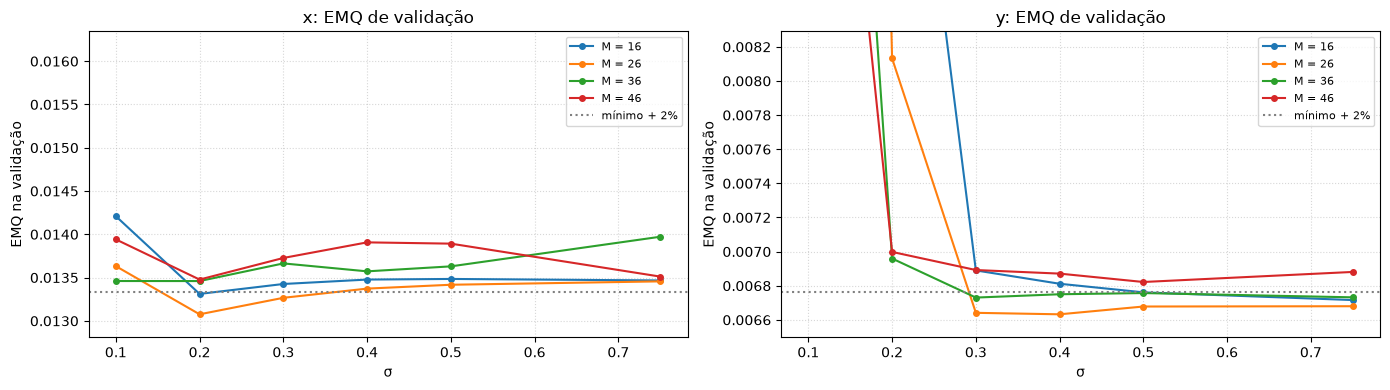

In [6]:
gerador = np.random.default_rng(0)
validacao = gerador.random(len(alvo_x)) < 0.2   # True em ~20% das linhas
treino = ~validacao

lista_por_estado = [5, 10, 15, 20]
lista_sigma = [0.1, 0.2, 0.3, 0.4, 0.5, 0.75]

escolha = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, (nome, Z, alvo) in enumerate([("x", Z_x, alvo_x), ("y", Z_y, alvo_y)]):
    tabela = np.zeros((len(lista_por_estado), len(lista_sigma)))
    for i, por_estado in enumerate(lista_por_estado):
        centros = escolher_centros(Z[treino], por_estado)
        for j, sigma in enumerate(lista_sigma):
            w = equacao_normal(matriz_phi(Z[treino], centros, sigma), alvo[treino])
            tabela[i, j] = emq(alvo[validacao], matriz_phi(Z[validacao], centros, sigma) @ w)

    limite = 1.02 * tabela.min()
    i, j = np.argwhere(tabela <= limite)[0]          # 1º que passa: menos centros, depois menor sigma
    escolha[nome] = (lista_por_estado[i], lista_sigma[j])

    print(f"EMQ de validação de {nome} (linhas: centros por estado | colunas: sigma = {lista_sigma})")
    for linha_i, por_estado in enumerate(lista_por_estado):
        print(f"  {por_estado:>2} por estado (M = {2 * por_estado + 6:>2}): {np.round(tabela[linha_i], 5)}")
    print(f"  -> escolhido: {escolha[nome][0]} por estado (M = {2 * escolha[nome][0] + 6}), sigma = {escolha[nome][1]}\n")

    for linha_i, por_estado in enumerate(lista_por_estado):
        ax[k].plot(lista_sigma, tabela[linha_i], "o-", ms=4, label=f"M = {2 * por_estado + 6}")
    ax[k].axhline(limite, color="0.5", ls=":", label="mínimo + 2%")
    ax[k].set_title(f"{nome}: EMQ de validação")
    ax[k].set_xlabel("σ")
    ax[k].set_ylabel("EMQ na validação")
    ax[k].set_ylim(tabela.min() * 0.98, tabela.min() * 1.25)
    ax[k].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4.4 Ajuste final e parâmetros livres do modelo RBF
Com o número de centros e o $\sigma$ escolhidos, escolhemos os centros usando **todas** as linhas e calculamos os pesos pela equação normal. A validação só serviu para escolher essas duas configurações.

**Parâmetros livres do modelo RBF:** os pesos $w_0, \dots, w_M$ (calculados), os centros $\mathbf c_j$ e a largura $\sigma$ (escolhidos).

RBF de x: M = 16 gaussianas | σ = 0.2 | 17 pesos (w0 + 16) | matriz Φ: 1499 x 17
  w0 = 0.0065
  alguns centros [s[n-1], s[n-2], u[n], u[n-1]] e seus pesos:
    c1  = [-0.416 -0.309  1.     1.   ]   w1 = -0.2499
    c2  = [-0.153 -0.131  1.     1.   ]   w2 = 0.0054
    c11 = [-0.199 -0.239  1.    -1.   ]   w11 = 0.0528
    c16 = [ 0.23   0.284 -1.     1.   ]   w16 = 0.2312
RBF de y: M = 16 gaussianas | σ = 0.5 | 17 pesos (w0 + 16) | matriz Φ: 1499 x 17
  w0 = -0.2782
  alguns centros [s[n-1], s[n-2], u[n], u[n-1]] e seus pesos:
    c1  = [-0.774 -0.609  1.     1.   ]   w1 = -0.3495
    c2  = [-0.191 -0.061  1.     1.   ]   w2 = 0.1558
    c11 = [-0.718 -0.782  1.    -1.   ]   w11 = -0.4002
    c16 = [ 0.56  0.44 -1.    1.  ]   w16 = 0.6553


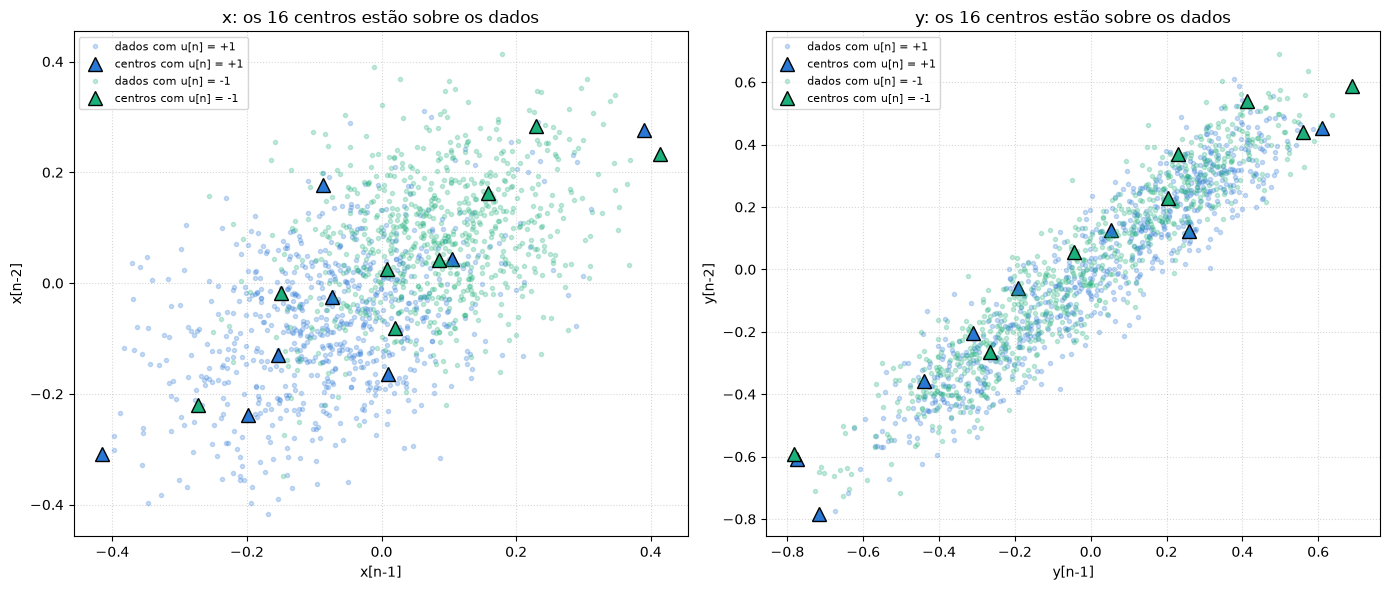

In [7]:
modelo_rbf = {}
for nome, Z, alvo in [("x", Z_x, alvo_x), ("y", Z_y, alvo_y)]:
    por_estado, sigma = escolha[nome]
    centros = escolher_centros(Z, por_estado)
    Phi = matriz_phi(Z, centros, sigma)
    w = equacao_normal(Phi, alvo)
    modelo_rbf[nome] = (centros, sigma, w)

    print(f"RBF de {nome}: M = {len(centros)} gaussianas | σ = {sigma} | {len(w)} pesos (w0 + {len(centros)})"
          f" | matriz Φ: {Phi.shape[0]} x {Phi.shape[1]}")
    print(f"  w0 = {w[0]:.4f}")
    print("  alguns centros [s[n-1], s[n-2], u[n], u[n-1]] e seus pesos:")
    for j in [0, 1, len(centros) - 6, len(centros) - 1]:
        print(f"    c{j + 1:<2} = {np.round(centros[j], 3)}   w{j + 1} = {w[j + 1]:.4f}")

x_rbf = matriz_phi(Z_x, modelo_rbf["x"][0], modelo_rbf["x"][1]) @ modelo_rbf["x"][2]
y_rbf = matriz_phi(Z_y, modelo_rbf["y"][0], modelo_rbf["y"][1]) @ modelo_rbf["y"][2]

# Gráfico: onde estão os centros (2 das 4 coordenadas; a cor indica u[n])
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, Z, nome in [(ax[0], Z_x, "x"), (ax[1], Z_y, "y")]:
    centros = modelo_rbf[nome][0]
    for valor_u, cor in [(1, COR_MEDIDO), (-1, "#1baf7a")]:
        sel = Z[:, 2] == valor_u
        a.plot(Z[sel, 0], Z[sel, 1], "o", ms=3, alpha=0.25, color=cor, label=f"dados com u[n] = {valor_u:+d}")
        selc = centros[:, 2] == valor_u
        a.plot(centros[selc, 0], centros[selc, 1], "^", ms=10, color=cor, markeredgecolor="k",
               label=f"centros com u[n] = {valor_u:+d}")
    a.set_xlabel(f"{nome}[n-1]")
    a.set_ylabel(f"{nome}[n-2]")
    a.set_title(f"{nome}: os {len(centros)} centros estão sobre os dados")
    a.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

Os triângulos (centros) estão **sobre a nuvem de dados**, cobrindo toda a faixa de valores. Os pontos ficam perto da diagonal porque $s[n-1]$ e $s[n-2]$ são amostras vizinhas (0,02 s de diferença), portanto quase iguais.

### 4.5 Etapas 01 e 02 — Ajuste obtido via RBF e EMQ
Cada previsão usa os **valores medidos** anteriores ($s[n-1]$ e $s[n-2]$ vêm dos dados). Isso se chama **predição um passo à frente**.

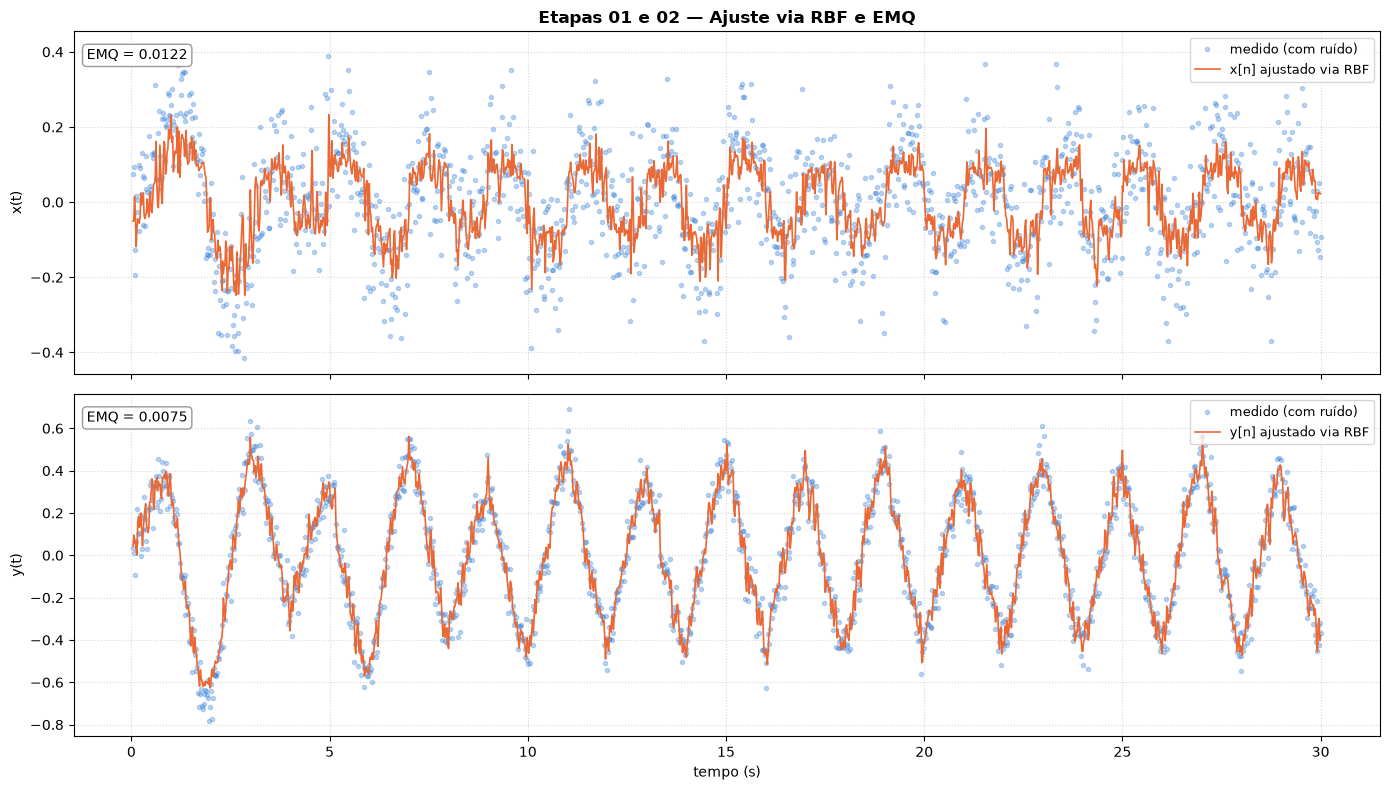

EMQ x (RBF) = 0.01222  ->  erro típico √EMQ = 0.1106
EMQ y (RBF) = 0.00752  ->  erro típico √EMQ = 0.0867


In [8]:
EMQ_x_rbf = emq(alvo_x, x_rbf)
EMQ_y_rbf = emq(alvo_y, y_rbf)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, ajuste, nome, e in [(ax[0], alvo_x, x_rbf, "x", EMQ_x_rbf), (ax[1], alvo_y, y_rbf, "y", EMQ_y_rbf)]:
    a.plot(t_alvo, medido, "o", ms=3, alpha=0.3, color=COR_MEDIDO, label="medido (com ruído)")
    a.plot(t_alvo, ajuste, color=COR_RBF, lw=1.2, label=f"{nome}[n] ajustado via RBF")
    a.text(0.01, 0.95, f"EMQ = {e:.4f}", transform=a.transAxes, va="top",
           bbox=dict(boxstyle="round", fc="white", ec="0.6"))
    a.set_ylabel(f"{nome}(t)")
    a.legend(loc="upper right", fontsize=9)
ax[0].set_title("Etapas 01 e 02 — Ajuste via RBF e EMQ", fontweight="bold")
ax[1].set_xlabel("tempo (s)")
plt.tight_layout()
plt.show()

print(f"EMQ x (RBF) = {EMQ_x_rbf:.5f}  ->  erro típico √EMQ = {np.sqrt(EMQ_x_rbf):.4f}")
print(f"EMQ y (RBF) = {EMQ_y_rbf:.5f}  ->  erro típico √EMQ = {np.sqrt(EMQ_y_rbf):.4f}")

A curva da RBF é **serrilhada**: ela recebe os valores medidos (com ruído) de $s[n-1]$ e $s[n-2]$, então parte do ruído passa para a previsão.

### 4.6 Etapa 03 — Regressão linear entre real e ajustado + Pearson
Cada ponto é um instante: no eixo horizontal o valor **ajustado**, no vertical o **medido**. Se o modelo fosse perfeito, todos os pontos estariam sobre a reta $y = \hat y$. A faixa colorida mostra $\pm\sqrt{\text{EMQ}}$ em torno da reta de regressão.

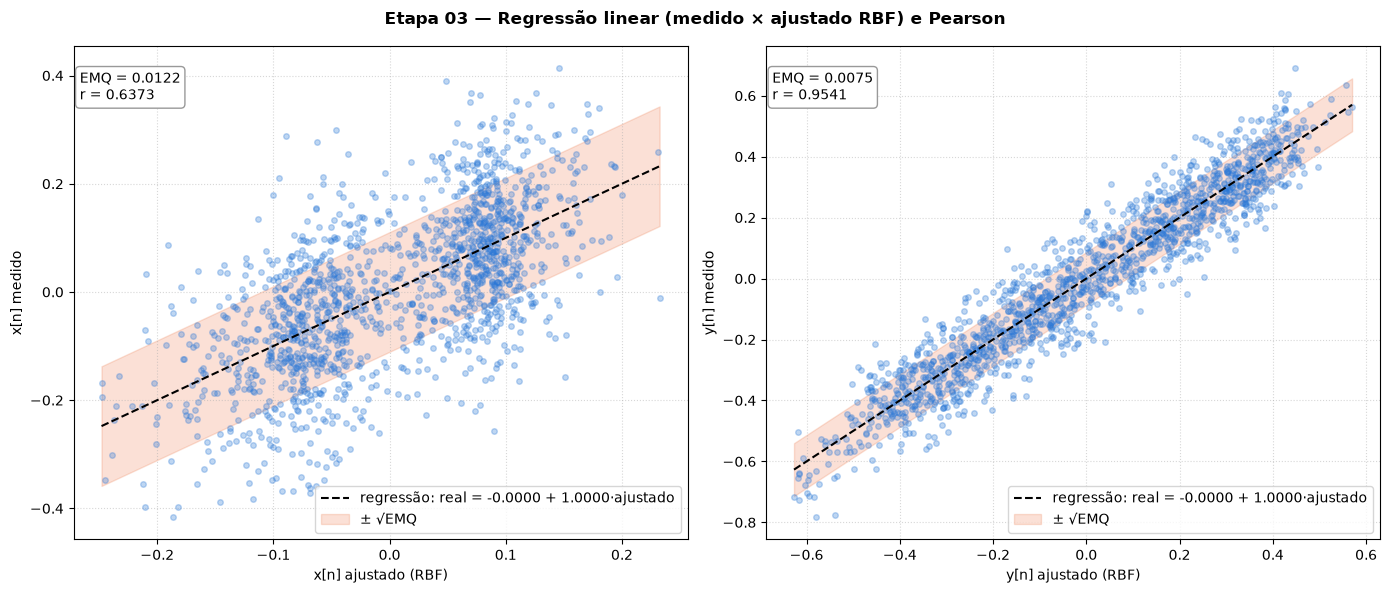

x: real = -0.0000 + 1.0000·ajustado | Pearson r = 0.6373 | r² = 0.4062
y: real = -0.0000 + 1.0000·ajustado | Pearson r = 0.9541 | r² = 0.9102


In [9]:
def grafico_regressao(ax, ajustado, real, nome, cor, rotulo_modelo):
    alfa, beta = regressao_linear(ajustado, real)
    r = pearson(real, ajustado)
    e = emq(real, ajustado)
    xs = np.linspace(ajustado.min(), ajustado.max(), 100)
    reta = alfa + beta * xs
    ax.plot(ajustado, real, "o", ms=4, alpha=0.3, color=COR_MEDIDO)
    ax.plot(xs, reta, "k--", lw=1.5, label=f"regressão: real = {alfa:.4f} + {beta:.4f}·ajustado")
    ax.fill_between(xs, reta - np.sqrt(e), reta + np.sqrt(e), color=cor, alpha=0.2, label="± √EMQ")
    ax.text(0.01, 0.95, f"EMQ = {e:.4f}\nr = {r:.4f}", transform=ax.transAxes, va="top",
            bbox=dict(boxstyle="round", fc="white", ec="0.6"))
    ax.set_xlabel(f"{nome}[n] ajustado ({rotulo_modelo})")
    ax.set_ylabel(f"{nome}[n] medido")
    ax.legend(loc="lower right")
    return alfa, beta, r

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
alfa_x_rbf, beta_x_rbf, r_x_rbf = grafico_regressao(ax[0], x_rbf, alvo_x, "x", COR_RBF, "RBF")
alfa_y_rbf, beta_y_rbf, r_y_rbf = grafico_regressao(ax[1], y_rbf, alvo_y, "y", COR_RBF, "RBF")
fig.suptitle("Etapa 03 — Regressão linear (medido × ajustado RBF) e Pearson", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"x: real = {alfa_x_rbf:.4f} + {beta_x_rbf:.4f}·ajustado | Pearson r = {r_x_rbf:.4f} | r² = {r_x_rbf**2:.4f}")
print(f"y: real = {alfa_y_rbf:.4f} + {beta_y_rbf:.4f}·ajustado | Pearson r = {r_y_rbf:.4f} | r² = {r_y_rbf**2:.4f}")

**Leitura:**
* Inclinação **1** e intercepto **0**: isso sempre acontece quando o modelo tem termo constante ($w_0$) e os pesos vêm do MMQ. O erro que sobra não tem tendência nenhuma em relação ao ajuste, então a melhor reta é $y = 0 + 1\cdot\hat y$. Ou seja, o ajuste **não tem viés**.
* O $r$ de $y$ é bem maior que o de $x$. Não quer dizer que o método funcionou pior em $x$: em $x$ o **ruído é quase do tamanho do sinal**, então nenhuma curva consegue acompanhar os pontos medidos de perto.

---
## 5. Repetição do processo com MMQ — Etapa 04

### 5.1 O modelo linear e seus parâmetros livres
Mesma função do enunciado, agora com $f$ **linear**:
$$\boxed{s[n] = a_1\,s[n-1] + a_2\,s[n-2] + b_0\,u[n] + b_1\,u[n-1]}$$
Os **parâmetros livres** são $a_1, a_2$ (quanto o passado da saída influencia o presente, a "memória" do sistema) e $b_0, b_1$ (quanto a entrada influencia). É uma **equação de diferenças** de 2ª ordem, a versão discreta de uma equação diferencial de 2ª ordem (como um massa-mola-amortecedor).

A matriz agora é a própria $Z$ (1499 linhas × 4 colunas). São 1499 equações para 4 incógnitas (sistema **sobredeterminado**, sem solução exata), e o MMQ escolhe os parâmetros que minimizam o EMQ pela mesma equação normal:
$$Z^TZ\,\theta = Z^T\mathbf s, \qquad \theta = (a_1, a_2, b_0, b_1)$$
**Diferença para a RBF:** na RBF as 4 entradas passam pelas gaussianas antes de entrar na matriz; no MMQ elas entram **diretamente**.

Parâmetros livres de s[n] = a1·s[n-1] + a2·s[n-2] + b0·u[n] + b1·u[n-1]

saída           a1        a2        b0        b1
x           0.2984    0.2118   -0.0216   -0.0150
y           0.4876    0.4649   -0.0159    0.0426


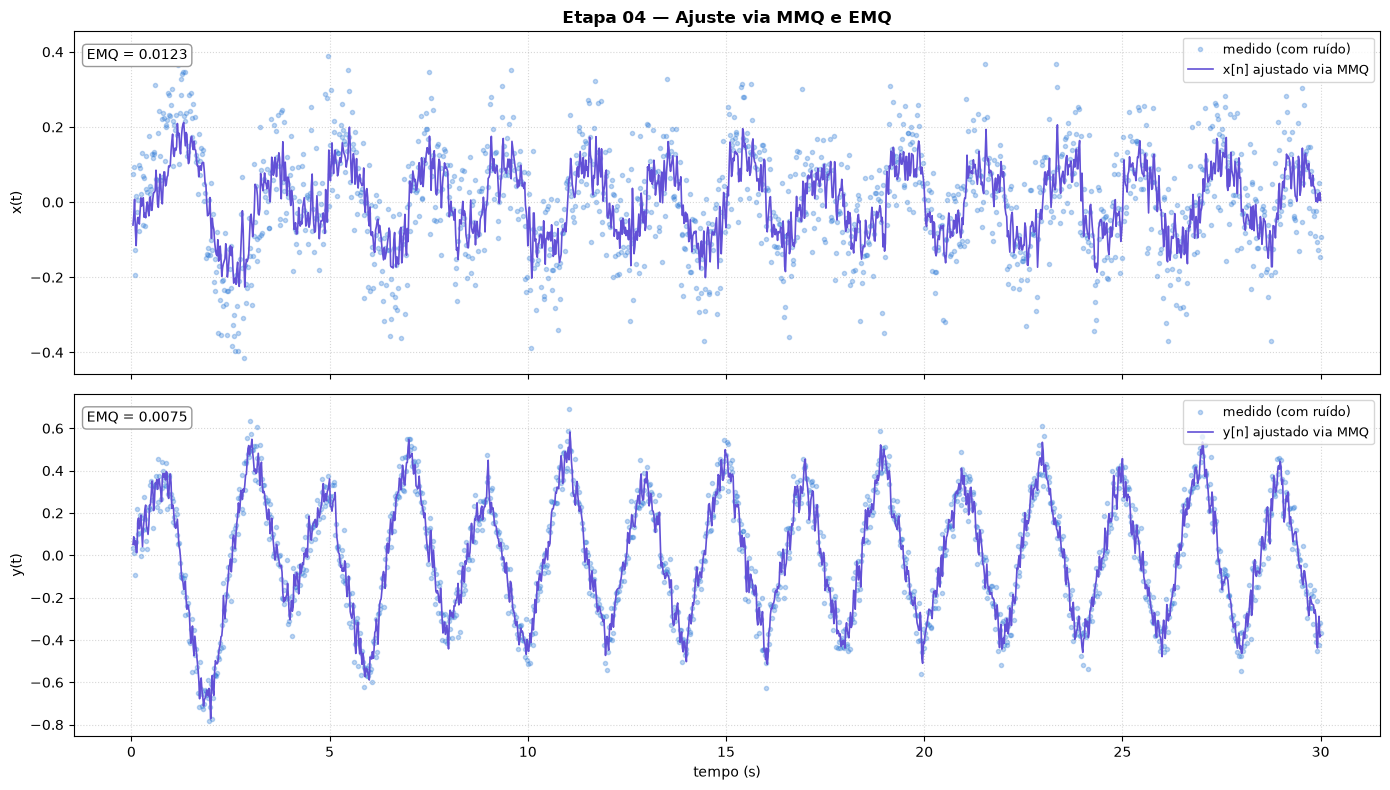


EMQ x (MMQ) = 0.01226  ->  erro típico √EMQ = 0.1107
EMQ y (MMQ) = 0.00753  ->  erro típico √EMQ = 0.0868


In [10]:
theta_x = equacao_normal(Z_x, alvo_x)
theta_y = equacao_normal(Z_y, alvo_y)

print("Parâmetros livres de s[n] = a1·s[n-1] + a2·s[n-2] + b0·u[n] + b1·u[n-1]\n")
print(f"{'saída':<8}{'a1':>10}{'a2':>10}{'b0':>10}{'b1':>10}")
for nome, th in [("x", theta_x), ("y", theta_y)]:
    print(f"{nome:<8}{th[0]:>10.4f}{th[1]:>10.4f}{th[2]:>10.4f}{th[3]:>10.4f}")

x_mmq = Z_x @ theta_x
y_mmq = Z_y @ theta_y
EMQ_x_mmq = emq(alvo_x, x_mmq)
EMQ_y_mmq = emq(alvo_y, y_mmq)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, ajuste, nome, e in [(ax[0], alvo_x, x_mmq, "x", EMQ_x_mmq), (ax[1], alvo_y, y_mmq, "y", EMQ_y_mmq)]:
    a.plot(t_alvo, medido, "o", ms=3, alpha=0.3, color=COR_MEDIDO, label="medido (com ruído)")
    a.plot(t_alvo, ajuste, color=COR_MMQ, lw=1.2, label=f"{nome}[n] ajustado via MMQ")
    a.text(0.01, 0.95, f"EMQ = {e:.4f}", transform=a.transAxes, va="top",
           bbox=dict(boxstyle="round", fc="white", ec="0.6"))
    a.set_ylabel(f"{nome}(t)")
    a.legend(loc="upper right", fontsize=9)
ax[0].set_title("Etapa 04 — Ajuste via MMQ e EMQ", fontweight="bold")
ax[1].set_xlabel("tempo (s)")
plt.tight_layout()
plt.show()

print(f"\nEMQ x (MMQ) = {EMQ_x_mmq:.5f}  ->  erro típico √EMQ = {np.sqrt(EMQ_x_mmq):.4f}")
print(f"EMQ y (MMQ) = {EMQ_y_mmq:.5f}  ->  erro típico √EMQ = {np.sqrt(EMQ_y_mmq):.4f}")

### 5.2 Regressão linear e Pearson do MMQ

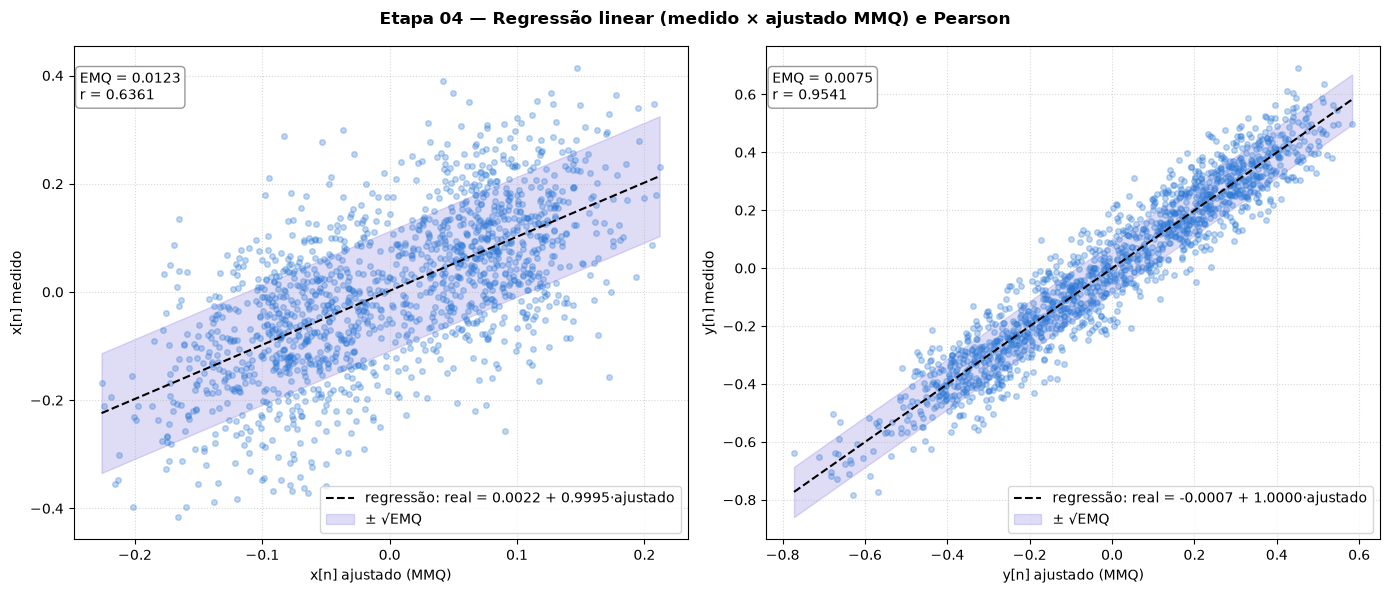

x: real = 0.0022 + 0.9995·ajustado | Pearson r = 0.6361 | r² = 0.4046
y: real = -0.0007 + 1.0000·ajustado | Pearson r = 0.9541 | r² = 0.9102


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
alfa_x_mmq, beta_x_mmq, r_x_mmq = grafico_regressao(ax[0], x_mmq, alvo_x, "x", COR_MMQ, "MMQ")
alfa_y_mmq, beta_y_mmq, r_y_mmq = grafico_regressao(ax[1], y_mmq, alvo_y, "y", COR_MMQ, "MMQ")
fig.suptitle("Etapa 04 — Regressão linear (medido × ajustado MMQ) e Pearson", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"x: real = {alfa_x_mmq:.4f} + {beta_x_mmq:.4f}·ajustado | Pearson r = {r_x_mmq:.4f} | r² = {r_x_mmq**2:.4f}")
print(f"y: real = {alfa_y_mmq:.4f} + {beta_y_mmq:.4f}·ajustado | Pearson r = {r_y_mmq:.4f} | r² = {r_y_mmq**2:.4f}")

Aqui a inclinação é só **quase** 1 e o intercepto **quase** 0: o modelo linear do enunciado **não tem termo constante**, então a propriedade vista na Seção 4.6 não vale de forma exata.

---
## 6. Os modelos conseguem simular o sistema sozinhos?

A justificativa do projeto é obter um modelo que **simule** a dinâmica do sistema. Nas seções 4 e 5, toda previsão recebia os valores **medidos** anteriores. O teste mais exigente é a **simulação livre**: o modelo recebe **só a entrada $u$** (e as duas primeiras amostras medidas) e usa as **próprias previsões** como passado:
$$\hat s[n] = f\big(\hat s[n-1],\, \hat s[n-2],\, u[n],\, u[n-1]\big)$$
Como os erros se acumulam de um passo para o outro, esse teste mostra se o modelo realmente aprendeu como o sistema reage à entrada.

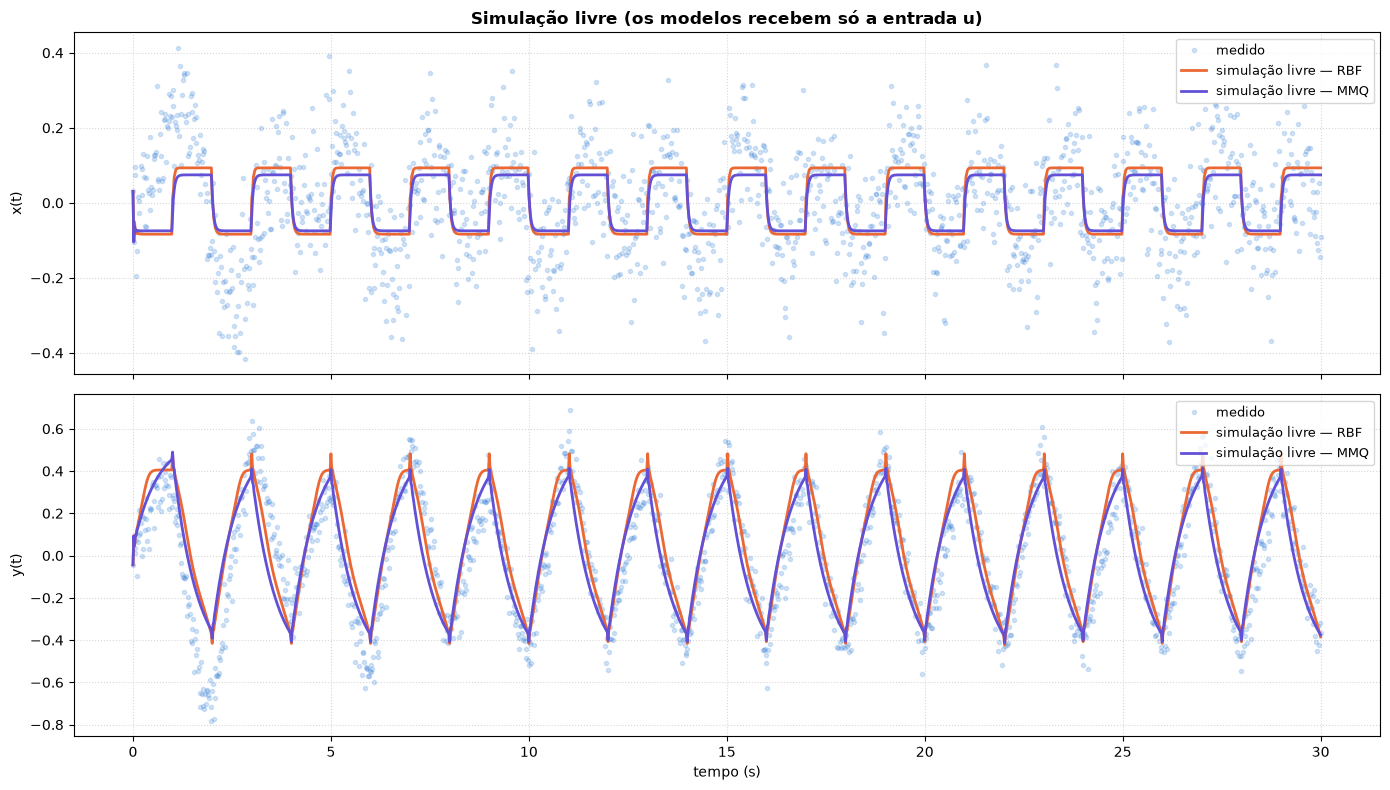

x: RBF livre EMQ = 0.01495, r = 0.5277  |  MMQ livre EMQ = 0.01497, r = 0.5238
y: RBF livre EMQ = 0.01853, r = 0.9141  |  MMQ livre EMQ = 0.01970, r = 0.8777


In [12]:
def simular_livre(prever, u, s_medido):
    s_sim = np.zeros(len(u))
    s_sim[0], s_sim[1] = s_medido[0], s_medido[1]           # só as 2 primeiras amostras vêm dos dados
    for n in range(2, len(u)):
        z = np.array([[s_sim[n - 1], s_sim[n - 2], u[n], u[n - 1]]])
        s_sim[n] = prever(z)[0]
    return s_sim

def prever_rbf(nome):
    centros, sigma, w = modelo_rbf[nome]
    return lambda z: matriz_phi(z, centros, sigma) @ w

def prever_mmq(theta):
    return lambda z: z @ theta

x_sim_rbf = simular_livre(prever_rbf("x"), u, x)
y_sim_rbf = simular_livre(prever_rbf("y"), u, y)
x_sim_mmq = simular_livre(prever_mmq(theta_x), u, x)
y_sim_mmq = simular_livre(prever_mmq(theta_y), u, y)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, s_rbf, s_mmq, nome in [(ax[0], x, x_sim_rbf, x_sim_mmq, "x"), (ax[1], y, y_sim_rbf, y_sim_mmq, "y")]:
    a.plot(t, medido, "o", ms=3, alpha=0.2, color=COR_MEDIDO, label="medido")
    a.plot(t, s_rbf, color=COR_RBF, lw=2, label="simulação livre — RBF")
    a.plot(t, s_mmq, color=COR_MMQ, lw=2, label="simulação livre — MMQ")
    a.set_ylabel(f"{nome}(t)")
    a.legend(loc="upper right", fontsize=9)
ax[0].set_title("Simulação livre (os modelos recebem só a entrada u)", fontweight="bold")
ax[1].set_xlabel("tempo (s)")
plt.tight_layout()
plt.show()

for nome, medido, s_rbf, s_mmq in [("x", x, x_sim_rbf, x_sim_mmq), ("y", y, y_sim_rbf, y_sim_mmq)]:
    print(f"{nome}: RBF livre EMQ = {emq(medido[2:], s_rbf[2:]):.5f}, r = {pearson(medido[2:], s_rbf[2:]):.4f}"
          f"  |  MMQ livre EMQ = {emq(medido[2:], s_mmq[2:]):.5f}, r = {pearson(medido[2:], s_mmq[2:]):.4f}")

---
## 7. Comparação final

In [13]:
print(f"{'Modelo':<34}{'Saída':<7}{'EMQ':>10}{'√EMQ':>9}{'Pearson r':>11}{'r²':>8}")
print("-" * 79)
linhas_tabela = [
    ("RBF - um passo à frente", "x", EMQ_x_rbf, r_x_rbf),
    ("RBF - um passo à frente", "y", EMQ_y_rbf, r_y_rbf),
    ("MMQ - um passo à frente", "x", EMQ_x_mmq, r_x_mmq),
    ("MMQ - um passo à frente", "y", EMQ_y_mmq, r_y_mmq),
    ("RBF - simulação livre",   "x", emq(x[2:], x_sim_rbf[2:]), pearson(x[2:], x_sim_rbf[2:])),
    ("RBF - simulação livre",   "y", emq(y[2:], y_sim_rbf[2:]), pearson(y[2:], y_sim_rbf[2:])),
    ("MMQ - simulação livre",   "x", emq(x[2:], x_sim_mmq[2:]), pearson(x[2:], x_sim_mmq[2:])),
    ("MMQ - simulação livre",   "y", emq(y[2:], y_sim_mmq[2:]), pearson(y[2:], y_sim_mmq[2:])),
]
for modelo, saida, e, r in linhas_tabela:
    print(f"{modelo:<34}{saida:<7}{e:>10.5f}{np.sqrt(e):>9.4f}{r:>11.4f}{r**2:>8.4f}")

print(f"\nParâmetros: RBF x = {len(modelo_rbf['x'][2])} pesos, RBF y = {len(modelo_rbf['y'][2])} pesos | MMQ = 4 por saída")

Modelo                            Saída         EMQ     √EMQ  Pearson r      r²
-------------------------------------------------------------------------------
RBF - um passo à frente           x         0.01222   0.1106     0.6373  0.4062
RBF - um passo à frente           y         0.00752   0.0867     0.9541  0.9102
MMQ - um passo à frente           x         0.01226   0.1107     0.6361  0.4046
MMQ - um passo à frente           y         0.00753   0.0868     0.9541  0.9102
RBF - simulação livre             x         0.01495   0.1223     0.5277  0.2784
RBF - simulação livre             y         0.01853   0.1361     0.9141  0.8357
MMQ - simulação livre             x         0.01497   0.1224     0.5238  0.2744
MMQ - simulação livre             y         0.01970   0.1404     0.8777  0.7703

Parâmetros: RBF x = 17 pesos, RBF y = 17 pesos | MMQ = 4 por saída


---
## 8. Conclusões

**1. Os dois métodos implementam o modelo do enunciado, $s[n] = f(s[n-1], s[n-2], u[n], u[n-1])$.** Na RBF, $f$ é uma soma de 16 gaussianas em 4 dimensões (17 pesos por saída); no MMQ, $f$ é uma combinação linear com 4 parâmetros. Nos dois casos os pesos saem da mesma equação normal.

**2. Na predição um passo à frente, RBF e MMQ empatam.**

| Saída | RBF: EMQ | RBF: $r$ | MMQ: EMQ | MMQ: $r$ |
|---|---|---|---|---|
| $x$ | 0,0122 | 0,637 | 0,0123 | 0,636 |
| $y$ | 0,0075 | 0,954 | 0,0075 | 0,954 |

A flexibilidade das gaussianas praticamente não ajuda. Isso indica que, com esse nível de ruído, a relação entre o passado e o próximo valor é **essencialmente linear**: o MMQ, com só 4 parâmetros, já captura quase tudo. Pelo princípio da parcimônia (entre modelos com o mesmo desempenho, preferir o mais simples), o modelo linear é suficiente para esse uso.

**3. Na simulação livre (o teste mais exigente), a RBF foi um pouco melhor em $y$.** Recebendo só a entrada $u$, a RBF reproduziu $y$ com EMQ = 0,0185 e $r = 0{,}914$, contra EMQ = 0,0197 e $r = 0{,}878$ do MMQ. Em $x$ os dois modelos ficam iguais e fracos (EMQ ≈ 0,0150 e $r \approx 0{,}52$).

**4. Por que a simulação de $x$ é fraca: ruído nas entradas do modelo.** As entradas $s[n-1]$ e $s[n-2]$ também são medidas com ruído. O MMQ então "confia pouco" no passado e diminui os coeficientes $a_1$ e $a_2$, que representam a memória do sistema:

| Saída | $a_1$ | $a_2$ | $b_0$ | $b_1$ | $a_1 + a_2$ |
|---|---|---|---|---|---|
| $x$ | 0,2984 | 0,2118 | −0,0216 | −0,0150 | 0,51 |
| $y$ | 0,4876 | 0,4649 | −0,0159 | 0,0426 | 0,95 |

Em $x$, onde o ruído é maior em relação ao sinal, a memória estimada é bem menor ($a_1 + a_2 = 0{,}51$). Com pouca memória, o modelo simulado de $x$ vira praticamente uma cópia da onda quadrada da entrada, com amplitude pequena, e não reproduz a forma real da resposta (gráfico da Seção 6).

**5. A saída $y$ é sempre melhor modelada que $x$.** É a **relação sinal/ruído**: em $x$ o erro típico ($\sqrt{\text{EMQ}} \approx 0{,}11$) é quase do tamanho da variação do próprio sinal; em $y$ o sinal varia de −0,78 a 0,69, bem mais que o erro típico ($\approx 0{,}09$).

**6. Os ajustes não têm viés.** Na regressão medido × ajustado, a RBF deu inclinação 1 e intercepto 0 (propriedade do MMQ com termo constante $w_0$); o MMQ deu 0,9995 e 0,0022 em $x$ e 1,0000 e −0,0007 em $y$.

**7. EMQ e Pearson se complementam.** O EMQ mede o **tamanho** do erro; o $r$ mede se a **forma** do sinal foi capturada. Usar os dois, junto com a reta de regressão ($\beta \approx 1$, $\alpha \approx 0$), dá uma avaliação mais completa do que qualquer um sozinho.

**Possíveis melhorias:** ajustar os modelos a partir de um sinal previamente filtrado, aumentar a ordem do modelo (mais valores passados) ou usar métodos próprios para ruído nas entradas.